## Open interest, positioning and liquidations

What the venues publish about the positions on Bitcoin's perpetual: open interest, the ratio
of long to short accounts, and the liquidations OKX serves, over the 30 days before the run,
the most Binance keeps. Each venue keeps its own span of these, so the window ends at the run
and its numbers move from one run to the next.

In [1]:
import exchange_router
import matplotlib.pyplot
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 3.0.0, exchange-router 3.3.0


### The window and the series

Up to the last whole hour: each venue's capabilities, hourly open interest and the ratio of
accounts at the four venues that keep 30 days of them, OKX's liquidations, and Binance's
bars as a probatum Data. `verbose=False` quiets the warnings that a venue's latest hour has
no close to put a dollar value on, that OKX and Kraken give the ratio alone, and that OKX's
liquidations come to fewer than `limit`.

In [2]:
SYMBOLS = {"binance": "BTCUSDT", "bybit": "BTCUSDT", "okx": "BTCUSDT",
           "kraken": "XBTUSD", "kucoin": "XBTUSDT", "hyperliquid": "BTCUSDC"}
KEEPING = ["binance", "bybit", "okx", "kraken"]

last   = pandas.Timestamp.now(tz="UTC").floor(freq="h") - pandas.Timedelta(hours=1)
newest = int(last.timestamp() * 1_000)

with exchange_router.Router.local(exchanges=list(SYMBOLS)) as router:
    capabilities = {exchange: router.get_capabilities(exchange=exchange)
                    for exchange in SYMBOLS}
    interest = {exchange: router.get_open_interest(exchange=exchange, market_type="linear",
                                                   symbol=SYMBOLS[exchange], period="1h",
                                                   limit=720, start=newest, verbose=False)
                for exchange in KEEPING}
    ratios = {exchange: router.get_long_short_ratio(exchange=exchange, market_type="linear",
                                                    symbol=SYMBOLS[exchange], period="1h",
                                                    limit=720, start=newest, verbose=False)
              for exchange in KEEPING}
    forced = router.get_liquidations(exchange="okx", market_type="linear", symbol="BTCUSDT",
                                     limit=5_000, start=newest + 3_599_999, verbose=False)
    data = probatum.Data.from_router(router, exchange="binance", market="linear",
                                     interval="1h", symbols=["BTCUSDT"],
                                     start=last - pandas.Timedelta(hours=719), end=last)

print(f"{data.provenance['first']} to {data.provenance['last']}, {len(data)} bars")

2026-10-09 17:00 to 2026-11-08 16:00, 720 bars


### What each venue keeps

Each route's history where the venue states one, in days.

In [3]:
ROUTES = ["open_interest", "long_short_ratio", "liquidations"]

kept = {}
for exchange, offered in capabilities.items():
    linear = offered["markets"]["linear"]
    kept[exchange] = {route: "none" if not linear[route]["rest"] else
                             "not stated" if linear[route]["retention_ms"] is None else
                             linear[route]["retention_ms"] / 86_400_000
                      for route in ROUTES}

pandas.DataFrame(kept).T

,open_interest,long_short_ratio,liquidations
binance,30.0,30.0,none
bybit,not stated,not stated,none
okx,30.0,30.0,1.0
kraken,not stated,not stated,none
kucoin,7.0,none,none
hyperliquid,not stated,none,none


### Open interest

In bitcoin, as each of the four reports it, on the hours all four have: the latest, and
its change over the window.

In [4]:
coins = pandas.DataFrame({exchange: frame["open_interest"]
                          for exchange, frame in interest.items()}).dropna()

pandas.DataFrame({"latest, BTC": coins.iloc[-1],
                  "change, %": (coins.iloc[-1] / coins.iloc[0] - 1.0) * 100}).round(
    decimals=2)

,"latest, BTC","change, %"
binance,96142.47,4.91
bybit,71007.18,25.99
okx,34604.13,15.07
kraken,2683.10,15.04


### Each venue against its own start

The four venues' open interest differ by a factor of forty, so each is drawn as its change
from the window's first hour.

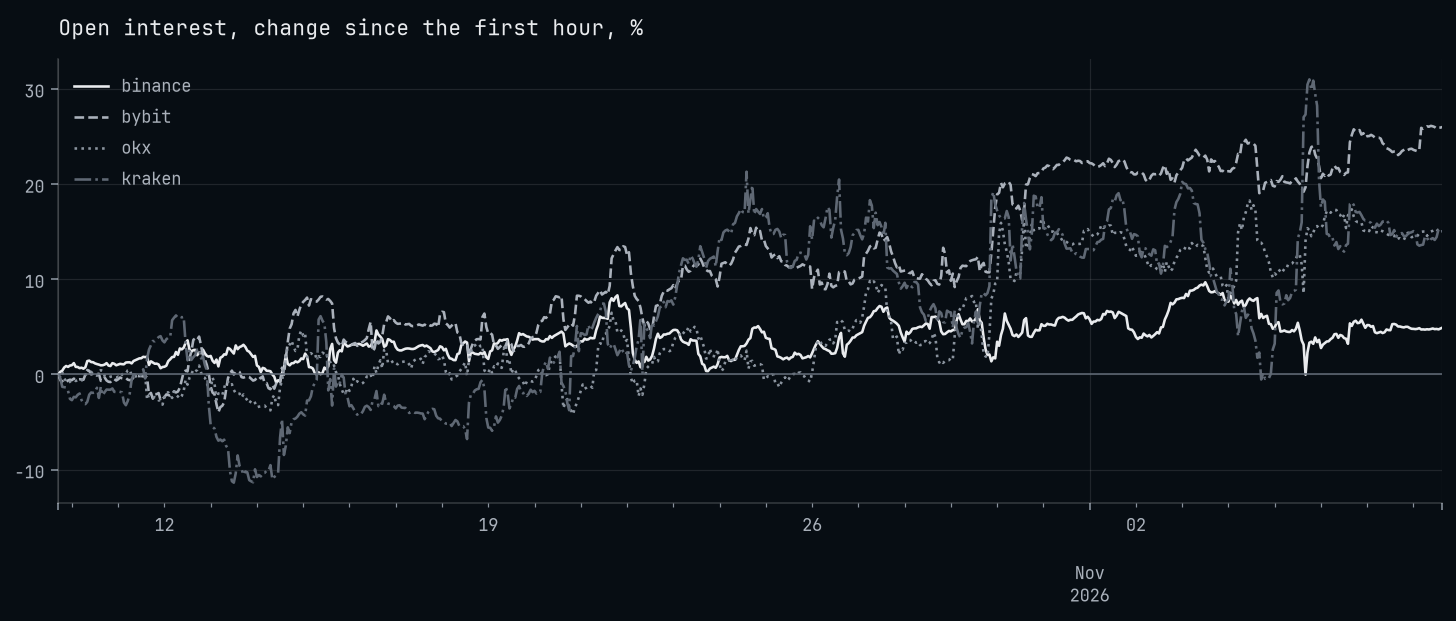

In [5]:
axes = (coins / coins.iloc[0] - 1.0).mul(100).plot(
    title="Open interest, change since the first hour, %", xlabel="")
axes.axhline(y=0.0, color="C3", linewidth=0.8)
matplotlib.pyplot.show()

### The ratio of long to short accounts

Binance and Bybit count every account and give its split; OKX and Kraken give the ratio
alone, by definitions of their own, which `account_scope` names.

{'binance': 'all_accounts', 'bybit': 'all_accounts', 'okx': 'opaque', 'kraken': 'opaque'}


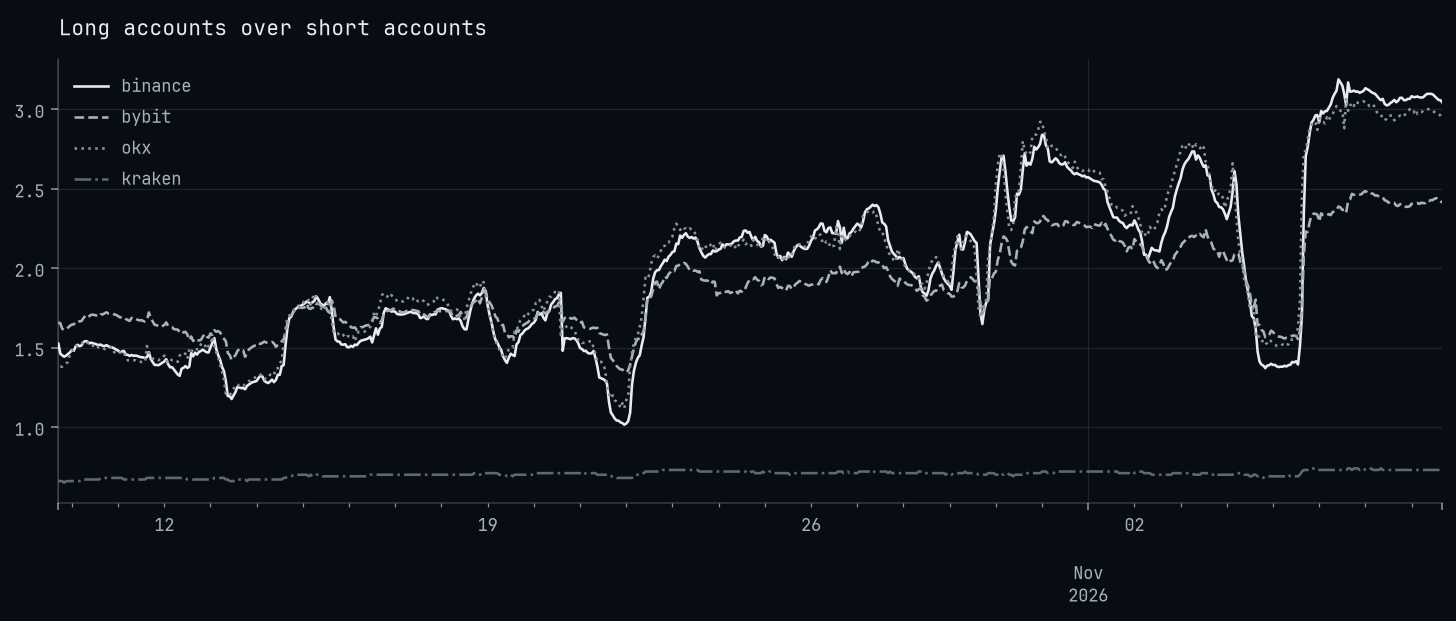

In [6]:
print({exchange: frame.attrs["account_scope"] for exchange, frame in ratios.items()})

axes = pandas.DataFrame({exchange: frame["ratio"] for exchange, frame in ratios.items()}).plot(
    title="Long accounts over short accounts", xlabel="")
matplotlib.pyplot.show()

### Liquidations

OKX serves the forced orders of the last day. A liquidation's side is the side of the order
that closed it, so a sell closed a long. Summed by hour, the longs closed are drawn below
zero and the shorts above.

83 liquidations from 2026-11-07 20:44 to 2026-11-08 16:57
      count     sum    max
side                      
buy      39  128093  54376
sell     44  166425  47078


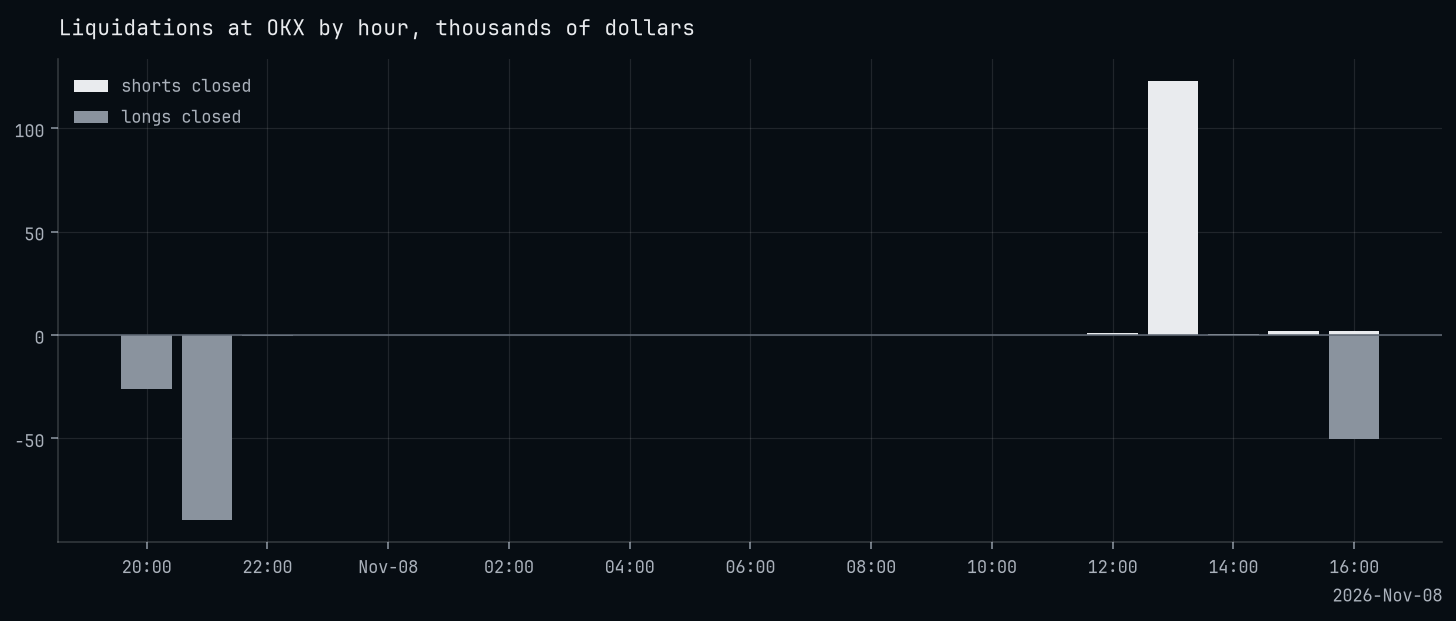

In [7]:
hourly = forced.groupby(by="side")["qty_usd"].resample(rule="1h").sum().unstack(level=0)

print(f"{len(forced):,} liquidations from {forced.index[0]:%Y-%m-%d %H:%M} "
      f"to {forced.index[-1]:%Y-%m-%d %H:%M}")
print(forced.groupby(by="side")["qty_usd"].agg(["count", "sum", "max"]).round().astype(int))

figure, axes = matplotlib.pyplot.subplots()
axes.bar(hourly.index, hourly.get("buy", 0.0) / 1e3, width=0.035, label="shorts closed")
axes.bar(hourly.index, -hourly.get("sell", 0.0) / 1e3, width=0.035, color="C2",
         label="longs closed")
axes.axhline(y=0.0, color="C3", linewidth=0.8)
axes.set_title(label="Liquidations at OKX by hour, thousands of dollars")
axes.legend(loc="upper left")
matplotlib.pyplot.show()

### Under the price

Binance's open interest and ratio of accounts put on its bars by `asof`, each value on the
bar at whose end it was known, then drawn on panels under the candles.

In [8]:
data.chart(
    probatum.chart.marks.Line(data.asof(interest["binance"]["open_interest"]),
                              name="open interest, BTC", panel="interest"),
    probatum.chart.marks.Line(data.asof(ratios["binance"]["ratio"]), name="long over short",
                              panel="accounts"),
    probatum.chart.marks.Level(value=1.0, panel="accounts", style="dotted"),
    focus=24 * 10,
    title="BTCUSDT perpetual at binance, 1h, the 30 days before the run",
)

Chart(bars=720, panels=4)